# Exploration : météo au sol et vue d'ensemble des tables propres

Ce notebook donne (1) une vue d'ensemble des tables propres, (2) un premier regard sur la table
`weather_daily` (NOAA GSOD, collectée par requêtes SQL dans BigQuery, nettoyée par
`auroracast.transform.gsod`) et (3) la table `weather_hourly` (NOAA GHCNh, mêmes stations), qui
prolonge la météo après l'arrêt de GSOD le 24/08/2025 et sert de contrôle croisé.

Mêmes prérequis que le notebook 01 (`data/clean` récupéré depuis la branche `clean-data`). Pour mettre
les tables à jour : `git -C data/clean fetch origin clean-data` puis
`git -C data/clean reset --hard origin/clean-data`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from auroracast.data import TABLES, load

COLORS = {"tromso": "#2a78d6", "kiruna": "#eb6834", "rovaniemi": "#1baf7a"}
NAMES = {"tromso": "Tromsø", "kiruna": "Kiruna", "rovaniemi": "Rovaniemi"}
ORDER = ["tromso", "kiruna", "rovaniemi"]
MONTHS = ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"]
MUTED, INK = "#52514e", "#0b0b0b"
SOURCE = "Source : NOAA NCEI, Global Surface Summary of the Day (GSOD), via BigQuery ; nettoyage AuroraCast"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

weather = load("weather_daily")
weather["day"] = pd.to_datetime(weather["day"])
hourly = load("weather_hourly")
SOURCE_H = "Source : NOAA NCEI, GHCNh (CC0) ; GSOD via BigQuery ; nettoyage AuroraCast"
weather.head()

,location,day,station_id,station_name,temp_c,temp_max_c,temp_min_c,dewpoint_c,rel_humidity_pct,visibility_km,...,precip_flag,precip_suspect,fog,rain,snow,hail,thunder,n_obs_temp,n_obs_visib,source
0,kiruna,2010-01-01,020440,KIRUNA,-18.67,-13.22,-25.00,-20.50,85.4,5.63,...,None,False,False,False,True,False,False,24,24,gsod
1,kiruna,2010-01-02,020440,KIRUNA,-21.50,-13.00,-25.61,-23.67,82.6,13.20,...,None,False,False,False,True,False,False,24,24,gsod
2,kiruna,2010-01-03,020440,KIRUNA,-14.83,-8.61,-24.00,-16.17,89.6,11.75,...,None,False,False,False,True,False,False,24,24,gsod
3,kiruna,2010-01-04,020440,KIRUNA,-19.44,-15.72,-25.28,-21.44,84.1,10.30,...,None,False,False,False,True,False,False,24,24,gsod
4,kiruna,2010-01-05,020440,KIRUNA,-16.28,-13.89,-25.11,-17.83,87.8,10.78,...,None,False,False,False,True,False,False,24,24,gsod


## 1. Vue d'ensemble des tables propres

Une ligne par table : nombre de lignes, première et dernière date couvertes.

In [2]:
TIME_COLUMNS = ["time", "day", "date", "target_time"]
rows = []
for name in TABLES:
    df = load(name)
    col = next((c for c in TIME_COLUMNS if c in df.columns), None)
    rows.append({
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "début": pd.to_datetime(df[col]).min().date() if col else "—",
        "fin": pd.to_datetime(df[col]).max().date() if col else "—",
    })
pd.DataFrame(rows).set_index("table")

,lignes,colonnes,début,fin
table,,,,
kp_3h,277082,5,1932-01-01,2026-10-29
solar_daily,34633,7,1932-01-01,2026-10-26
solar_wind_hourly,147489,10,2010-01-01,2026-10-29
kp_forecast,54,6,2026-10-27,2026-11-01
locations,3,6,—,—
cloud_hourly,442119,9,2010-01-01,2026-10-24
weather_daily,17145,23,2010-01-01,2025-08-24
weather_hourly,442120,17,2010-01-01,2026-10-24


## 2. Complétude de la météo au sol

Part des jours où chaque mesure existe, par lieu (2010-2025). Plus la case est foncée, plus la mesure
est complète. Les précipitations ne sont exploitables qu'à Tromsø : à Kiruna et à Rovaniemi, presque
tous les jours portent la lettre NOAA « I » (pas de relevé), passée à vide au nettoyage.

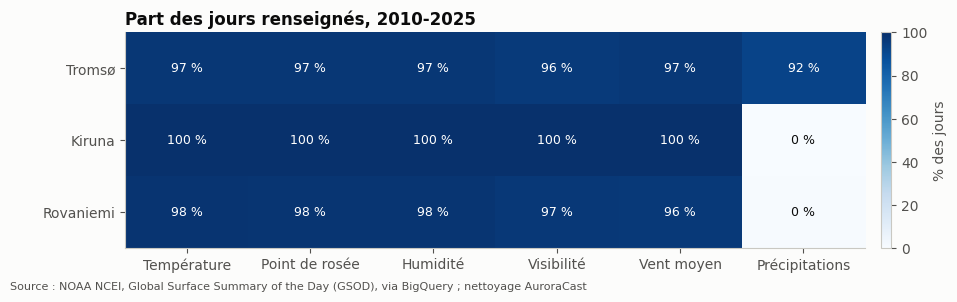

,Température,Point de rosée,Humidité,Visibilité,Vent moyen,Précipitations
location,,,,,,
Tromsø,96.9,96.9,96.9,95.9,96.7,92.3
Kiruna,99.6,99.5,99.5,99.5,99.6,0.0
Rovaniemi,98.1,98.0,98.0,96.6,96.4,0.4


In [3]:
variables = {"temp_c": "Température", "dewpoint_c": "Point de rosée",
             "rel_humidity_pct": "Humidité", "visibility_km": "Visibilité",
             "wind_mean_ms": "Vent moyen", "precip_mm": "Précipitations"}
present = (weather.groupby("location")[list(variables)].agg(lambda s: s.notna().mean()) * 100)
present = present.loc[ORDER].rename(index=NAMES, columns=variables)

fig, ax = plt.subplots(figsize=(10, 2.8))
im = ax.imshow(present.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(present.shape[1]), present.columns)
ax.set_yticks(range(present.shape[0]), present.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(present.values):
    ax.text(j, i, f"{v:.0f} %", ha="center", va="center", fontsize=9,
            color="white" if v > 60 else INK)
ax.set_title("Part des jours renseignés, 2010-2025")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="% des jours")
fig.text(0.01, -0.04, SOURCE, fontsize=8, color=MUTED)
plt.show()
present.round(1)

## 3. Température au fil de l'année

Moyenne de la température quotidienne par mois ; la bande montre où tombent 80 % des jours
(du 10e au 90e centile). La saison des aurores (septembre à mars) est grisée.

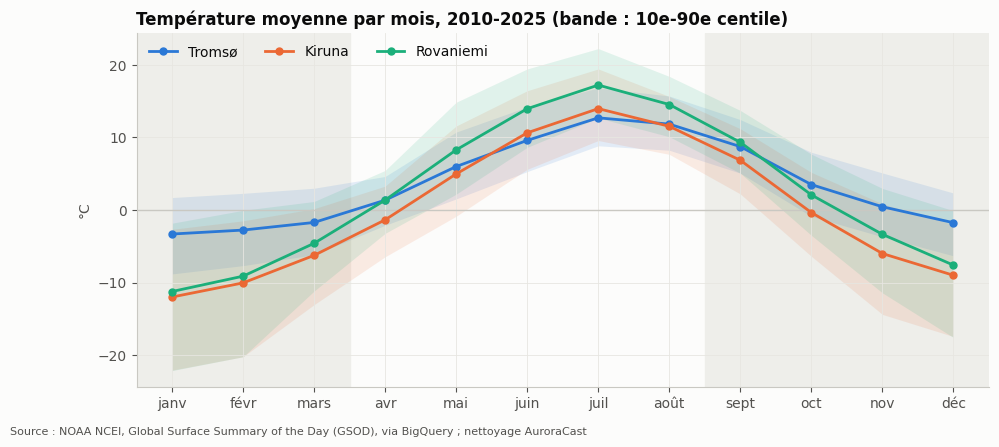

location,Tromsø,Kiruna,Rovaniemi
month,,,
janv,-3.3,-12.0,-11.2
févr,-2.8,-10.0,-9.1
mars,-1.7,-6.3,-4.6
avr,1.3,-1.4,1.4
mai,6.0,5.0,8.3
juin,9.6,10.6,13.9
juil,12.7,14.0,17.2
août,11.8,11.5,14.5
sept,8.7,6.8,9.3


In [4]:
w = weather.assign(month=weather["day"].dt.month)
stats = w.groupby(["location", "month"])["temp_c"].describe(percentiles=[0.1, 0.9])

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axvspan(0.5, 3.5, color="#eeeeea", zorder=0)
ax.axvspan(8.5, 12.5, color="#eeeeea", zorder=0)
ax.axhline(0, color="#c9c8c2", linewidth=1)
for loc in ORDER:
    s = stats.loc[loc]
    ax.fill_between(s.index, s["10%"], s["90%"], color=COLORS[loc], alpha=0.12, linewidth=0)
    ax.plot(s.index, s["mean"], color=COLORS[loc], linewidth=2, marker="o", markersize=5,
            label=NAMES[loc])
ax.set_xticks(range(1, 13), MONTHS)
ax.set_xlim(0.5, 12.5)
ax.set_ylabel("°C")
ax.set_title("Température moyenne par mois, 2010-2025 (bande : 10e-90e centile)")
ax.legend(frameon=False, loc="upper left", ncols=3)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color=MUTED)
plt.show()
stats["mean"].unstack(0)[ORDER].round(1).rename(index=dict(enumerate(MONTHS, 1)), columns=NAMES)

## 4. Brouillard : nombre moyen de jours par mois

Un jour de brouillard est un jour où la station a signalé du brouillard au moins une fois. Le brouillard
masque le ciel aussi sûrement qu'une couche de nuages : c'est une variable utile au modèle.

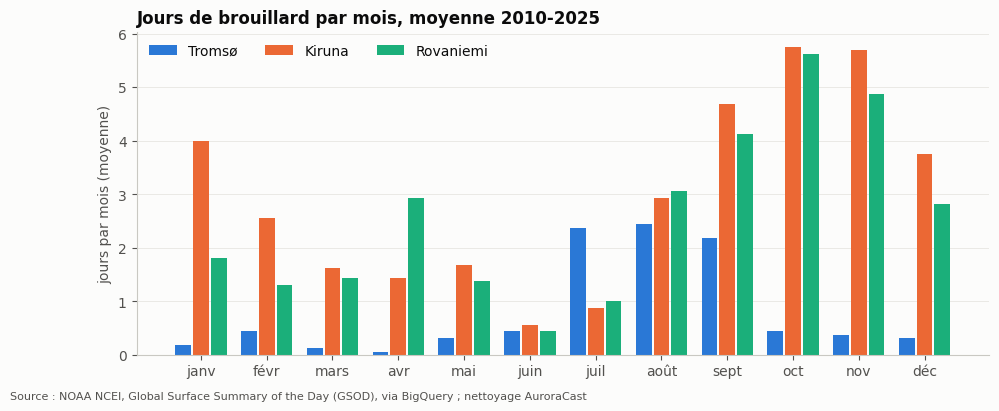

location,Tromsø,Kiruna,Rovaniemi
month,,,
janv,0.2,4.0,1.8
févr,0.4,2.6,1.3
mars,0.1,1.6,1.4
avr,0.1,1.4,2.9
mai,0.3,1.7,1.4
juin,0.4,0.6,0.4
juil,2.4,0.9,1.0
août,2.4,2.9,3.1
sept,2.2,4.7,4.1


In [5]:
years = w["day"].dt.year.nunique()
fog = (w.groupby(["month", "location"])["fog"].sum().unstack()[ORDER] / years)

fig, ax = plt.subplots(figsize=(11, 4.2))
width = 0.27
for k, loc in enumerate(ORDER):
    ax.bar(np.arange(1, 13) + (k - 1) * width, fog[loc], width=width - 0.03,
           color=COLORS[loc], label=NAMES[loc], zorder=2)
ax.set_xticks(range(1, 13), MONTHS)
ax.set_ylabel("jours par mois (moyenne)")
ax.set_title("Jours de brouillard par mois, moyenne 2010-2025")
ax.legend(frameon=False, loc="upper left", ncols=3)
ax.grid(axis="x", visible=False)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color=MUTED)
plt.show()
fog.round(1).rename(index=dict(enumerate(MONTHS, 1)), columns=NAMES)

## 5. Précipitations à Tromsø : les jours suspects

Cumul quotidien de précipitations à Tromsø. En orange, les jours marqués `precip_suspect` au
nettoyage : plus de 50 mm sans pluie, neige ni grêle signalée ce jour-là (cumul de plusieurs jours
probable). Ils sont gardés dans la table mais signalés, pour que le modèle puisse les écarter.

À noter : une dizaine de jours dépassent aussi 50 mm avec de la pluie signalée (points bleus au-dessus
du seuil) et les très gros cumuls apparaissent surtout après 2016. Les précipitations ne seront donc
utilisées qu'avec prudence, et seulement pour Tromsø.

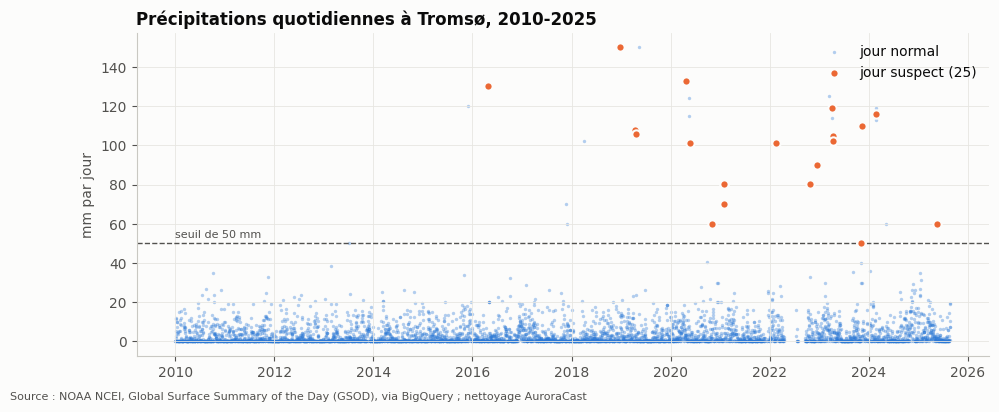

,day,precip_mm,precip_flag,temp_c
14706,2018-12-21,150.11,G,-0.61
15194,2020-04-22,133.10,G,3.56
13738,2016-04-27,130.05,G,8.17
16273,2023-04-06,119.13,G,5.39
16596,2024-02-23,116.08,G,0.39
16495,2023-11-14,109.98,G,-3.89
14823,2019-04-17,107.95,G,2.39
14824,2019-04-18,105.92,G,4.22
16277,2023-04-10,104.90,G,2.67
16279,2023-04-12,102.11,G,4.06


In [6]:
t = weather[(weather["location"] == "tromso") & weather["precip_mm"].notna()]
ok, bad = t[~t["precip_suspect"].fillna(False)], t[t["precip_suspect"].fillna(False)]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.scatter(ok["day"], ok["precip_mm"], s=6, color=COLORS["tromso"], alpha=0.35,
           linewidths=0, label="jour normal")
ax.scatter(bad["day"], bad["precip_mm"], s=36, color="#eb6834", edgecolor="#fcfcfb",
           linewidths=1.5, label=f"jour suspect ({len(bad)})", zorder=3)
ax.axhline(50, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("seuil de 50 mm", (t["day"].min(), 50), xytext=(0, 4), textcoords="offset points",
            fontsize=8, color=MUTED)
ax.set_ylabel("mm par jour")
ax.set_title("Précipitations quotidiennes à Tromsø, 2010-2025")
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, 0.005, SOURCE, fontsize=8, color=MUTED)
plt.show()
bad[["day", "precip_mm", "precip_flag", "temp_c"]].sort_values("precip_mm", ascending=False).head(10)

## 6. Contrôle croisé : GHCNh horaire contre GSOD quotidien

Les deux sources viennent des mêmes stations. On recalcule la température moyenne de chaque jour à
partir des relevés horaires GHCNh (jours avec au moins 18 heures) et on la compare à la moyenne publiée
par GSOD. Si le nettoyage horaire est correct, les points tombent sur la diagonale.

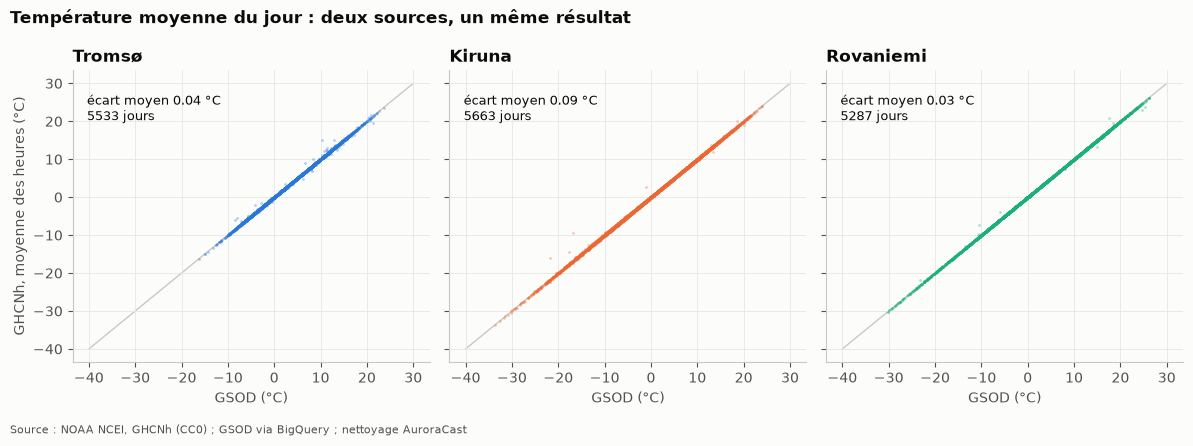

,count,mean,std,min,25%,50%,75%,max
location,,,,,,,,
kiruna,5663.0,0.086,0.163,0.0,0.024,0.060,0.115,7.220
rovaniemi,5287.0,0.026,0.088,0.0,0.009,0.018,0.027,3.370
tromso,5533.0,0.040,0.128,0.0,0.009,0.018,0.030,4.645


In [7]:
h = hourly[hourly["temp_c"].notna()].assign(day=lambda d: d["time"].dt.tz_localize(None).dt.normalize())
per_day = h.groupby(["location", "day"])["temp_c"].agg(["mean", "size"]).reset_index()
per_day = per_day[per_day["size"] >= 18]
cmp_ = per_day.merge(weather[["location", "day", "temp_c"]], on=["location", "day"]).dropna()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True)
for ax, loc in zip(axes, ORDER):
    g = cmp_[cmp_["location"] == loc]
    diff = (g["mean"] - g["temp_c"]).abs()
    ax.plot([-40, 30], [-40, 30], color="#c9c8c2", linewidth=1, zorder=1)
    ax.scatter(g["temp_c"], g["mean"], s=4, color=COLORS[loc], alpha=0.35, linewidths=0, zorder=2)
    ax.set_title(NAMES[loc])
    ax.text(0.04, 0.92, f"écart moyen {diff.mean():.2f} °C\n{len(g)} jours", transform=ax.transAxes,
            fontsize=9, va="top")
    ax.set_xlabel("GSOD (°C)")
axes[0].set_ylabel("GHCNh, moyenne des heures (°C)")
fig.suptitle("Température moyenne du jour : deux sources, un même résultat", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, -0.03, SOURCE_H, fontsize=8, color=MUTED)
fig.tight_layout()
plt.show()
cmp_.assign(ecart=lambda d: (d["mean"] - d["temp_c"]).abs()).groupby("location")["ecart"].describe().round(3)

## 7. Données récentes : GHCNh prend le relais de GSOD

Nombre de jours de chaque mois avec une température observée, pour chaque source. GSOD s'arrête en
août 2025 ; GHCNh continue jusqu'à la dernière mise à jour quotidienne.

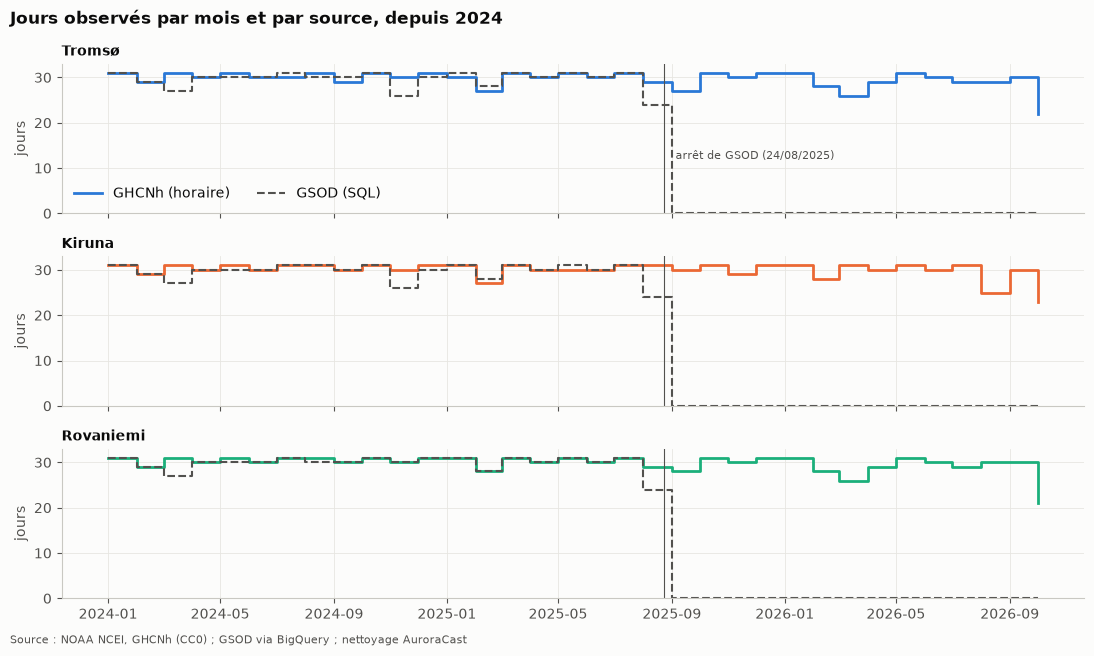

Dernière heure observée : {'kiruna': Timestamp('2026-10-24 13:00:00+0000', tz='UTC'), 'rovaniemi': Timestamp('2026-10-24 12:00:00+0000', tz='UTC'), 'tromso': Timestamp('2026-10-24 12:00:00+0000', tz='UTC')}


In [8]:
gsod_m = (weather[weather["temp_c"].notna()].assign(month=lambda d: d["day"].dt.to_period("M"))
          .groupby(["location", "month"]).size())
ghcnh_m = (per_day.assign(month=lambda d: d["day"].dt.to_period("M"))
           .groupby(["location", "month"]).size())
months = pd.period_range("2024-01", pd.Timestamp.now(tz="UTC").tz_localize(None).to_period("M"), freq="M")

fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), sharex=True, sharey=True)
x = months.to_timestamp()
for ax, loc in zip(axes, ORDER):
    a = gsod_m.get(loc, pd.Series(dtype=float)).reindex(months, fill_value=0)
    b = ghcnh_m.get(loc, pd.Series(dtype=float)).reindex(months, fill_value=0)
    ax.step(x, b.values, where="post", color=COLORS[loc], linewidth=2, label="GHCNh (horaire)")
    ax.step(x, a.values, where="post", color=MUTED, linewidth=1.5, linestyle="--", label="GSOD (SQL)")
    ax.set_title(NAMES[loc], fontsize=10)
    ax.set_ylim(0, 33)
    ax.set_ylabel("jours")
axes[0].legend(frameon=False, loc="lower left", ncols=2)
axes[0].annotate("arrêt de GSOD (24/08/2025)", (pd.Timestamp("2025-08-24"), 12), xytext=(8, 0),
                 textcoords="offset points", fontsize=8, color=MUTED)
for ax in axes:
    ax.axvline(pd.Timestamp("2025-08-24"), color=MUTED, linewidth=0.8)
fig.suptitle("Jours observés par mois et par source, depuis 2024", x=0.01, ha="left", fontweight="bold",
             fontsize=12)
fig.text(0.01, -0.01, SOURCE_H, fontsize=8, color=MUTED)
fig.tight_layout()
plt.show()
print("Dernière heure observée :", hourly.groupby("location")["time"].max().to_dict())